# CDS → upstream retrieval — can a model pick the right upstream for a gene?

**Panel A** 1-in-100 retrieval in *E. coli* with the full 300 bp upstream, for three models:
C3P embedding (contrastively trained protein ↔ upstream), Evo-1-8k likelihood **scoring**
(rank candidates by log P(CDS | upstream)), and Evo-1-8k mean-pooled **embedding** (cosine
between the CDS and each candidate upstream).

**Panel B** the same retrieval for C3P alone as the upstream is truncated to 200 / 100 / 50 bp,
always keeping the bases **proximal** to the start codon. Specificity collapses as the window
shrinks, so most of the gene-specific signal sits in the **distal** part of the upstream.

The metric on both panels is the **rank of the true upstream among 100 candidates** (1 = correct,
chance median = 50.5), averaged over the 20 retrieval repeats to give one paired observation
per gene.

Data were produced in the `Contrastive_Learning_NeurIPS2026` project and **copied** (not moved)
into `data/cds_upstream_retrieval/`; the original analysis scripts are copied alongside in
`code/cds_upstream_retrieval/` for provenance.

Outputs → `results/cds_upstream_retrieval/fig_cds_upstream_retrieval.{pdf,png}`

## Setup

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# repo root: works from the notebook (code/) and on Isambard alike
ROOT = Path.cwd()
while not (ROOT / "data" / "cds_upstream_retrieval").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "cds_upstream_retrieval"
OUT_DIR = ROOT / "results" / "cds_upstream_retrieval"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(ROOT)

${ICBINB_ROOT}


### Configuration

In [2]:
SPECIES = "Escherichia coli"          # E. coli only, per the paper panel
PANEL_A_LENGTH = 300                  # full upstream window used in panel A
PANEL_B_LENGTHS = [200, 100, 50]      # truncation sweep; add 300 here for the full window
N_CANDIDATES = 100                    # 1-in-100 retrieval -> chance median rank = 50.5
CHANCE_MEDIAN = (N_CANDIDATES + 1) / 2
SEED = 20260803                       # jitter only

MODELS = [
    # key,     file,                        metric,  label,                   colour
    ("c3p",   "c3p_length_ranks.parquet",   None,    "C3P\nembedding",        "#2166AC"),
    ("evo_s", "evo8k_score_ranks.parquet",  "cds",   "Evo-1\nscoring",        "#1B7837"),
    ("evo_e", "evo8k_embed_ranks.parquet",  None,    "Evo-1\nembedding",      "#762A83"),
]

INK = "#1a1a1a"
GREY = "#8C8C8C"
# panel B: one blue per length, fading as the window shrinks
LEN_COLOR = {300: "#08306B", 200: "#2166AC", 100: "#6BAED6", 50: "#BDD7E7"}
# darker twin of LEN_COLOR, for text that has to stay legible on white
LEN_TEXT = {300: "#08306B", 200: "#2166AC", 100: "#3182BD", 50: "#6BAED6"}
YMAX = 340.0                          # log-scale headroom for the significance brackets

### Style — shared with the other ICBINB figures (thick axes, Arial, type-42 fonts)

In [3]:
def set_style() -> None:
    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
        "mathtext.fontset": "dejavusans",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
        "figure.dpi": 110,
        "savefig.dpi": 400,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.25,
        "axes.linewidth": 2.2,
        "axes.edgecolor": INK,
        "xtick.major.width": 2.2,
        "ytick.major.width": 2.2,
        "xtick.minor.width": 1.3,
        "ytick.minor.width": 1.3,
        "xtick.major.size": 7.0,
        "ytick.major.size": 7.0,
        "xtick.minor.size": 3.5,
        "ytick.minor.size": 3.5,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.color": INK,
        "ytick.color": INK,
        "axes.labelcolor": INK,
        "text.color": INK,
        "axes.labelsize": 13,
        "axes.labelweight": "bold",
        "axes.titlesize": 13,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 10,
        "legend.frameon": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,
        "lines.solid_capstyle": "round",
    })

set_style()

## Data

Each parquet row is `(species, length, gene_row, rep, rank)`. Panel A restricts all three
models to the genes they share — the Evo scoring run used a 150-gene subsample of the C3P
gene set — so the model comparison is properly paired. Panel B uses all 727 E. coli genes.

In [4]:
def per_gene(df: pd.DataFrame, length: int, metric: str | None = None) -> pd.DataFrame:
    """Collapse the 20 retrieval repeats to one number per gene.

    Each row of the source parquet is (species, length, gene_row, rep, rank);
    `rank` is 1 = the true upstream was the top hit out of 100 candidates.
    Averaging over repeats removes decoy-draw noise and leaves one paired
    observation per gene, which is what the boxplots and the Wilcoxon test use.
    """
    sub = df[(df["species"] == SPECIES) & (df["length"] == length)]
    if metric is not None:
        sub = sub[sub["metric"] == metric]
    out = sub.groupby("gene_row")["rank"].agg(
        mean_rank="mean", top1=lambda s: (s == 1).mean()
    )
    return out


def load(data_dir: Path) -> tuple[dict[str, pd.DataFrame], pd.DataFrame, list[int]]:
    """Panel A per-gene table per model (on shared genes), plus the C3P sweep."""
    raw = {k: pd.read_parquet(data_dir / f) for k, f, _, _, _ in MODELS}

    panel_a = {k: per_gene(raw[k], PANEL_A_LENGTH, m) for k, _, m, _, _ in MODELS}
    # the Evo scoring run used a 150-gene subsample of the C3P gene set; restrict
    # all three models to the shared genes so panel A is a paired comparison
    shared = sorted(set.intersection(*(set(t.index) for t in panel_a.values())))
    panel_a = {k: t.loc[shared] for k, t in panel_a.items()}

    panel_b = pd.concat(
        {L: per_gene(raw["c3p"], L) for L in PANEL_B_LENGTHS}, names=["length", "gene_row"]
    ).reset_index()
    return panel_a, panel_b, shared

In [5]:
panel_a, panel_b, shared = load(DATA_DIR)

summary = pd.DataFrame([
    dict(panel="A", model=lab.replace("\n", " "), length_bp=PANEL_A_LENGTH, n=len(shared),
         median_rank=panel_a[k]["mean_rank"].median(),
         q1=panel_a[k]["mean_rank"].quantile(.25), q3=panel_a[k]["mean_rank"].quantile(.75),
         top1_pct=panel_a[k]["top1"].mean() * 100)
    for k, _, _, lab, _ in MODELS
] + [
    dict(panel="B", model="C3P embedding", length_bp=L,
         n=int((panel_b.length == L).sum()),
         median_rank=panel_b.loc[panel_b.length == L, "mean_rank"].median(),
         q1=panel_b.loc[panel_b.length == L, "mean_rank"].quantile(.25),
         q3=panel_b.loc[panel_b.length == L, "mean_rank"].quantile(.75),
         top1_pct=panel_b.loc[panel_b.length == L, "top1"].mean() * 100)
    for L in PANEL_B_LENGTHS
])
summary.round(2)

,panel,model,length_bp,n,median_rank,q1,q3,top1_pct
0,A,C3P embedding,300,150,1.00,1.00,1.00,87.77
1,A,Evo-1 scoring,300,150,13.88,4.94,45.02,15.57
2,A,Evo-1 embedding,300,150,42.18,16.64,69.58,0.87
3,B,C3P embedding,200,727,1.00,1.00,1.05,84.87
4,B,C3P embedding,100,727,1.10,1.00,4.43,61.31
5,B,C3P embedding,50,727,23.10,5.95,49.28,11.28


## Drawing helpers

In [6]:
def stars(p: float) -> str:
    return ("****" if p < 1e-4 else "***" if p < 1e-3 else
            "**" if p < 1e-2 else "*" if p < 0.05 else "n.s.")


def boxes(ax, values: list[np.ndarray], colors: list[str], positions=None):
    """Thick-lined boxplot with the raw per-gene points jittered on top."""
    pos = list(range(1, len(values) + 1)) if positions is None else positions
    bp = ax.boxplot(
        values, positions=pos, widths=0.56, patch_artist=True, showfliers=False,
        medianprops=dict(color=INK, lw=3.0, solid_capstyle="butt"),
        whiskerprops=dict(color=INK, lw=2.0),
        capprops=dict(color=INK, lw=2.0),
        boxprops=dict(lw=2.0, edgecolor=INK),
        zorder=3,
    )
    for patch, col in zip(bp["boxes"], colors):
        patch.set_facecolor(col)
        patch.set_alpha(0.55)

    rng = np.random.default_rng(SEED)
    for x, v, col in zip(pos, values, colors):
        jx = x + rng.uniform(-0.19, 0.19, size=len(v))
        ax.scatter(jx, v, s=8, color=col, alpha=0.28, linewidths=0, zorder=2, rasterized=True)
    return bp


def rank_axis(ax) -> None:
    ax.set_yscale("log")
    ax.set_ylim(0.80, YMAX)
    ax.set_yticks([1, 2, 5, 10, 20, 50, 100])
    ax.set_yticklabels(["1", "2", "5", "10", "20", "50", "100"])
    ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
    ax.axhline(CHANCE_MEDIAN, ls=(0, (5, 4)), lw=2.0, color=GREY, zorder=1)
    ax.text(0.015, CHANCE_MEDIAN * 1.09, "chance", transform=ax.get_yaxis_transform(),
            ha="left", va="bottom", fontsize=10.5, color=GREY)
    ax.grid(axis="y", lw=0.8, color="#E6E6E6", zorder=0)


def top1_row(ax, xs, tops, colors, y: float) -> None:
    """Top-1 accuracy printed under each box, below the x tick labels."""
    tr = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    for x, t, col in zip(xs, tops, colors):
        ax.text(x, y, f"top-1 {t:.0f}%", transform=tr, ha="center", va="top",
                fontsize=11, fontweight="bold", color=col, clip_on=False)


def better_arrow(ax) -> None:
    """`better` pointing down the rank axis, in the gutter left of the y label."""
    ax.annotate("", xy=(-0.105, 0.30), xytext=(-0.105, 0.66), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=2.0, color=GREY))
    ax.text(-0.135, 0.48, "better", rotation=90, va="center", ha="center",
            fontsize=10.5, color=GREY, transform=ax.transAxes)


def panel_label(ax, letter: str, dx: float = -0.17, dy: float = 1.13) -> None:
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=18,
            fontweight="bold", va="top", ha="left", color=INK)


def sig_bracket(ax, x1: float, x2: float, y: float, text: str, h: float = 1.13) -> None:
    ax.plot([x1, x1, x2, x2], [y, y * h, y * h, y], lw=1.8, color=INK, clip_on=False)
    ax.text((x1 + x2) / 2, y * h * 1.03, text, ha="center", va="bottom",
            fontsize=12, color=INK, clip_on=False)

## The figure

Significance is a one-sided paired Wilcoxon signed-rank test on the per-gene mean ranks
(panel A: C3P vs each Evo readout; panel B: the longest window shown vs each truncation).
`**** = p < 1e-4`.

In [7]:
def make_figure(panel_a: dict[str, pd.DataFrame], panel_b: pd.DataFrame,
                n_shared: int) -> tuple[plt.Figure, pd.DataFrame]:
    set_style()
    fig, axes = plt.subplots(1, 2, figsize=(12.2, 5.4))

    # ---------------- panel A : model comparison ---------------------------- #
    ax = axes[0]
    keys = [k for k, *_ in MODELS]
    labels = [lab for *_, lab, _ in MODELS]
    colors = [c for *_, c in MODELS]
    vals = [panel_a[k]["mean_rank"].to_numpy() for k in keys]
    boxes(ax, vals, colors)
    rank_axis(ax)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(labels)
    ax.set_ylabel("Rank of the true upstream\n(1 of 100 candidates)", labelpad=26)
    ax.set_title(f"$\\it{{E.\\ coli}}$ · {PANEL_A_LENGTH} bp upstream\n"
                 f"n = {n_shared} genes, 20 retrieval repeats", fontsize=12, pad=38)
    top1_row(ax, [1, 2, 3], [panel_a[k]["top1"].mean() * 100 for k in keys],
             colors, y=-0.155)
    better_arrow(ax)

    # paired Wilcoxon, C3P vs each Evo readout (one-sided: C3P rank lower)
    tests = []
    for k in keys[1:]:
        stat, p = wilcoxon(panel_a["c3p"]["mean_rank"], panel_a[k]["mean_rank"],
                           alternative="less", zero_method="wilcox")
        tests.append(dict(comparison=f"c3p_vs_{k}", wilcoxon_stat=float(stat),
                          p_one_sided=float(p), stars=stars(p)))
    sig_bracket(ax, 1, 2, 122, tests[0]["stars"])
    sig_bracket(ax, 1, 3, 205, tests[1]["stars"])
    panel_label(ax, "A")

    # ---------------- panel B : C3P upstream truncation --------------------- #
    ax = axes[1]
    vals_b, cols_b, tops = [], [], []
    for L in PANEL_B_LENGTHS:
        sub = panel_b[panel_b["length"] == L]
        vals_b.append(sub["mean_rank"].to_numpy())
        cols_b.append(LEN_COLOR[L])
        tops.append(sub["top1"].mean() * 100)
    boxes(ax, vals_b, cols_b)
    rank_axis(ax)
    xs = list(range(1, len(PANEL_B_LENGTHS) + 1))
    ax.set_xticks(xs)
    ax.set_xticklabels([f"{L}" for L in PANEL_B_LENGTHS])
    ax.set_xlabel("Upstream retained (bp, proximal to the start codon)", labelpad=30)
    ax.set_ylabel("Rank of the true upstream\n(1 of 100 candidates)", labelpad=26)
    n_b = panel_b[panel_b["length"] == PANEL_B_LENGTHS[0]].shape[0]
    ax.set_title(f"C3P embedding · $\\it{{E.\\ coli}}$\n"
                 f"n = {n_b} genes, 20 retrieval repeats", fontsize=12, pad=38)
    top1_row(ax, xs, tops, [LEN_TEXT[L] for L in PANEL_B_LENGTHS], y=-0.10)
    better_arrow(ax)

    # paired Wilcoxon against the longest window shown (same genes throughout)
    ref = PANEL_B_LENGTHS[0]
    wide = panel_b.pivot(index="gene_row", columns="length", values="mean_rank")
    for i, L in enumerate(PANEL_B_LENGTHS[1:], start=1):
        stat, p = wilcoxon(wide[ref], wide[L], alternative="less", zero_method="wilcox")
        tests.append(dict(comparison=f"c3p_{ref}bp_vs_{L}bp", wilcoxon_stat=float(stat),
                          p_one_sided=float(p), stars=stars(p)))
        sig_bracket(ax, 1, i + 1, 122 if i == 1 else 205, stars(p))
    # direction of the manipulation, sitting between the title and the axes
    ax.annotate("", xy=(0.95, 1.045), xytext=(0.05, 1.045), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=2.2, color=INK))
    ax.text(0.5, 1.065, "more of the distal upstream removed", transform=ax.transAxes,
            ha="center", va="bottom", fontsize=11, color=INK)
    panel_label(ax, "B")

    fig.tight_layout(w_pad=5.0)
    return fig, pd.DataFrame(tests)

wrote ${ICBINB_ROOT}/results/cds_upstream_retrieval/fig_cds_upstream_retrieval.pdf and .png


,comparison,wilcoxon_stat,p_one_sided,stars
0,c3p_vs_evo_s,150.0,6.080864e-23,****
1,c3p_vs_evo_e,13.0,2.182838e-26,****
2,c3p_200bp_vs_100bp,5433.5,4.658335e-50,****
3,c3p_200bp_vs_50bp,1352.0,6.743325e-113,****


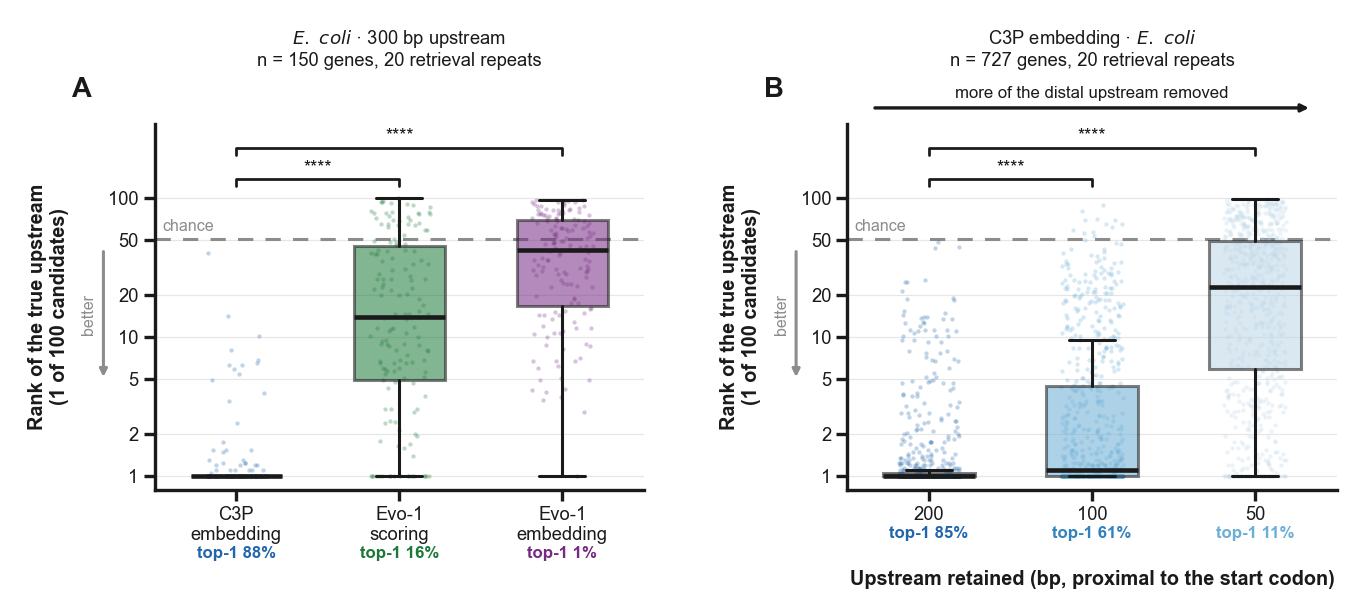

In [8]:
fig, tests = make_figure(panel_a, panel_b, len(shared))
for ext in ("pdf", "png"):
    fig.savefig(OUT_DIR / f"fig_cds_upstream_retrieval.{ext}")
summary.to_csv(OUT_DIR / "fig_cds_upstream_retrieval_summary.csv", index=False)
tests.to_csv(OUT_DIR / "fig_cds_upstream_retrieval_stats.csv", index=False)
print(f"wrote {OUT_DIR}/fig_cds_upstream_retrieval.pdf and .png")
tests

## Read-out

- **Panel A** — only C3P, which was contrastively trained to align a protein with its own
  upstream, retrieves the cognate upstream (top-1 88 %, median rank 1). Evo-1 scoring is well
  above chance but weak (top-1 16 %, median rank ≈ 14), and Evo-1 mean-pooled embeddings sit at
  chance (top-1 1 %, median rank ≈ 42) — a generative DNA LM does not, by itself, link a coding
  region to its own promoter.
- **Panel B** — truncating the upstream toward the start codon costs C3P little down to 200 bp,
  some at 100 bp, and nearly everything at 50 bp (top-1 85 → 61 → 11 %). The gene-specific
  signal therefore lives mostly in the **distal** upstream, not in the ~50 bp immediately 5′ of
  the start codon.

Set `PANEL_B_LENGTHS = [300, 200, 100, 50]` in the configuration cell to add the full 300 bp
window to panel B.